# 07 Scenariji ukrepov po četrtnih skupnostih: "kaj če" (odločevalci, igrifikacija)

**Namen:** preprost, pregleden model, s katerim odločevalec (ali igralec) preizkusi ukrepe: zamenjava starih peči v izbrani ČS, priključitev na vročevod, manj prometa, elektrifikacija, prepoved kurjenja ob epizodah, regionalni ukrepi. Model vrne, za koliko se zniža zimsko povprečje PM2.5 po ČS, koliko dni nad mejo odpade in koliko stane. Vse so **ocene z eksplicitnimi predpostavkami**, ki so zbrane v dveh celicah (`VIRI` in `CENE`), da jih lahko vsakdo spremeni.

**Ciljna skupina:** odločevalci in mestni načrtovalci (namen izziva: *spodbuditi* ciljno usmerjene ukrepe); igrifikacija za občane.

**Vhodi:** `cs_kazalniki.csv` iz zvezka 04 (ocena kurišč, stanovanja, lega po ČS), dnevni PM2.5 Bežigrad zima 2025/26 (meritev ARSO) kot izhodiščni potek.

**Pomembno:** deleži virov zimskega PM2.5 za mesto kot celoto so vzeti **po redu velikosti iz objavljenih ocen** (ARSO, IJS) in niso rezultat meritev za vsako ČS; emisijski inventar ARSO (`04_prostor/emisije/`) daje emisije, ne koncentracij, enote za promet pa še niso potrjene, zato deležev ne nadomešča. **Prostorska razporeditev prispevka kurišč po ČS** pa je od 20. 11. iz modela **GRAL ARSO** (prispevek kurišč h koncentraciji, 15 m, kurilna sezona), s stikalom `PROSTOR_KURISCA` v celici `VIRI` (`"gral"`, `"emisije"` ali `"ocena"` iz zvezka 04). Rezultati so zaokroženi; razlike pod 10 % so znotraj negotovosti modela.

In [1]:
import warnings; warnings.filterwarnings("ignore")
import sys; sys.path.insert(0, ".")
from paket import *
import geopandas as gpd
import matplotlib.pyplot as plt
plt.rcParams["figure.dpi"] = 100
pd.set_option("display.width", 180)

k = pd.read_csv("cs_kazalniki.csv").set_index("cs_ime")
cs = gpd.read_file(P/"04_prostor/mol_cetrtne_skupnosti.geojson")
cs["cs_ime"] = cs.cs_ime.str.replace("ČETRTNA SKUPNOST ", "").str.title()
k[["stanovanja", "kurisca_trda_ocena", "kurisca_na_km2", "delez_pod_30m"]].round(1).sort_values("kurisca_trda_ocena", ascending=False)

,stanovanja,kurisca_trda_ocena,kurisca_na_km2,delez_pod_30m
cs_ime,,,,
Sostro,2656.0,1781.9,20.1,0.1
Polje,7533.0,1677.0,75.9,0.8
Rudnik,5950.0,1451.8,57.0,0.9
Šentvid,5736.0,1281.4,80.9,0.2
Trnovo,6956.0,1059.0,147.6,1.0
Rožnik,7587.0,964.5,115.4,0.5
Šmarna Gora,1961.0,938.8,65.1,0.2
Črnuče,4968.0,823.0,45.5,0.7
Vič,6775.0,789.1,54.9,0.9


## 1. Predpostavke modela: deleži virov in prostorska razporeditev

Model je linearen: koncentracija je vsota prispevkov virov in vsak prispevek je sorazmeren emisijam tega vira. Lokalni prispevek malih kurišč v ČS je razporejen po **modelu GRAL** (prispevek kurišč h koncentraciji po ČS v kurilni sezoni; za Sostro, ki ga mreža slabo pokrije, po emisijah), lahko pa izberete razporeditev po emisijskem inventarju ARSO ali po oceni kurišč iz zvezka 04. Promet in drugi lokalni viri so po ČS enaki (uteži `PROMET_UTEZ` lahko spremenite), regionalno ozadje je povsod enako. Vsota po mestu je umerjena tako, da je prebivalstveno uteženo povprečje enako izmerjenemu zimskemu povprečju na Bežigradu.

In [2]:
VIRI = {   # delež zimskega PM2.5 na mestnem ozadju (red velikosti; izhodišče: ocene ARSO/IJS za kurilno sezono v Ljubljani)
    "mala_kurisca_trda":          0.45,   # kurjenje lesa in premoga v gospodinjstvih (lokalno, po ČS sorazmerno gostoti kurišč)
    "promet_izpuh":               0.08,   # izpušni delci (lokalno; odpravi elektrifikacija)
    "promet_obraba_resuspenzija": 0.10,   # zavore, gume, cestni prah (lokalno; elektrifikacija NE pomaga, manj prometa DA)
    "drugo_lokalno":              0.07,   # plinski/oljni kotli, industrija, gradbišča
    "regionalno_sekundarno":      0.30,   # prenos iz okolice in sekundarni aerosol (mesto nanj ne vpliva)
}
assert abs(sum(VIRI.values()) - 1) < 1e-9
PROSTOR_KURISCA = "gral"                          # "gral" (model ARSO, koncentracija), "emisije" (inventar ARSO, kg/km2) ali "ocena" (zvezek 04, kurišča/km2)
PROMET_UTEZ = {c: 1.0 for c in k.index}          # relativna prometna obremenitev po ČS (1 = mestno povprečje); spremenite po presoji
PROMET_UTEZ.update({"Center": 1.3, "Bežigrad": 1.2, "Šiška": 1.2, "Moste": 1.2, "Sostro": 0.6, "Šmarna Gora": 0.6})
EF_NOVA_PROTI_STARI = 0.25                        # emisije PM nove peči/kotla proti stari (0,1–0,3 po literaturi)
MEJA_DAN = 15                                     # µg/m³, WHO smernica za dnevno PM2.5 (EU 2030 letno 10; dnevna meja za PM2.5 ni predpisana)

pm = nalozi_arso(["E403"]).drop(columns="station_code")
dn = dnevno(pm); dn = dn[(dn.dan >= "2025-11-01") & (dn.dan < "2026-04-01")].dropna(subset=["pm25"])
C_MESTO = dn.pm25.mean()
print(f"izhodišče: Bežigrad zima 2025/26, {len(dn)} dni, povprečje PM2.5 {C_MESTO:.1f} µg/m³, dni nad {MEJA_DAN}: {(dn.pm25 > MEJA_DAN).sum()}, nad 25: {(dn.pm25 > 25).sum()}")

izhodišče: Bežigrad zima 2025/26, 151 dni, povprečje PM2.5 18.6 µg/m³, dni nad 15: 89, nad 25: 33


## 2. Izhodiščno stanje po ČS (ocena)

Relativni prispevek kurišč `r_c` je vrednost ČS (GRAL, emisije ali ocena, glede na `PROSTOR_KURISCA`) proti prebivalstveno uteženemu mestnemu povprečju, omejen na 0,3–2,5, da posamezna ČS ne dobi nesmiselnih vrednosti. Prispevek malih kurišč v ČS je `VIRI × C_MESTO × r_c`. Tabela pokaže, kako se `r_c` razlikuje po treh virih: tam, kjer se GRAL in inventar razhajata, je to razlika med "kje se kuri" in "kje se to pozna v zraku".

prostorska razporeditev prispevka kurišč: gral


cs_ime,Center,Trnovo,Moste,Bežigrad,Rožnik,Šiška,Vič,Jarše,Golovec,Rudnik,Polje,Dravlje,Šentvid,Posavje,Črnuče,Šmarna Gora,Sostro
gral,1.69,1.66,1.16,1.16,1.07,1.07,0.90,0.84,0.80,0.68,0.65,0.55,0.55,0.54,0.39,0.35,0.30
emisije,0.65,2.54,0.69,1.02,0.84,1.14,0.95,1.51,0.75,1.00,1.15,0.86,0.96,0.39,0.42,1.88,0.33
ocena,0.63,2.06,1.17,1.05,1.61,1.17,0.76,0.83,0.53,0.79,1.06,0.85,1.13,0.59,0.63,0.91,0.30


prebivalstveno uteženo povprečje po ČS: 18.6 µg/m³ (= izmerjeno na Bežigradu)


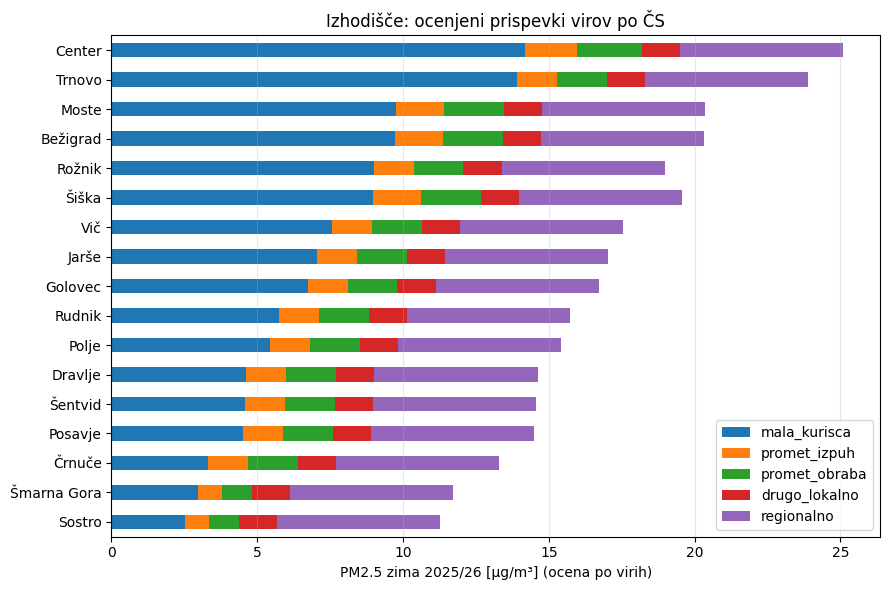

In [3]:
w = k.stanovanja / k.stanovanja.sum()                                  # prebivalstvena utež (približek: stanovanja)
gral_ali = k.gral_pm10_kurilna.fillna(k.gral_pm10_kurilna.mean() * k.emisije_kg_na_km2 / k.emisije_kg_na_km2.mean())  # Sostro: po emisijah
OSNOVA = {"gral": gral_ali, "emisije": k.emisije_kg_na_km2, "ocena": k.kurisca_na_km2}
def rel(x): x = (x / (x * w).sum()).clip(0.3, 2.5); return x / (x * w).sum()   # relativno na uteženo povprečje, omejeno, ponovno umerjeno
r = rel(OSNOVA[PROSTOR_KURISCA])
print(f"prostorska razporeditev prispevka kurišč: {PROSTOR_KURISCA}")
display(pd.DataFrame({n: rel(v) for n, v in OSNOVA.items()}).round(2).sort_values(PROSTOR_KURISCA, ascending=False).T)
pu = pd.Series(PROMET_UTEZ); pu = pu / (pu * w).sum()

def prispevki(zamenjava=None, vrocevod=None, promet_manj=0.0, elektrifikacija=0.0, regionalni=0.0):
    """Vrne DataFrame prispevkov virov po ČS (µg/m³) za izhodišče ali scenarij."""
    z = pd.Series(zamenjava or {}, dtype=float).reindex(k.index).fillna(0)
    v = pd.Series(vrocevod or {}, dtype=float).reindex(k.index).fillna(0)
    kur = VIRI["mala_kurisca_trda"] * C_MESTO * r * (1 - v) * (1 - z * (1 - EF_NOVA_PROTI_STARI))
    izp = VIRI["promet_izpuh"] * C_MESTO * pu * (1 - promet_manj) * (1 - elektrifikacija)
    obr = VIRI["promet_obraba_resuspenzija"] * C_MESTO * pu * (1 - promet_manj)
    dru = pd.Series(VIRI["drugo_lokalno"] * C_MESTO, index=k.index)
    reg = pd.Series(VIRI["regionalno_sekundarno"] * C_MESTO * (1 - regionalni), index=k.index)
    return pd.DataFrame({"mala_kurisca": kur, "promet_izpuh": izp, "promet_obraba": obr, "drugo_lokalno": dru, "regionalno": reg})

base = prispevki()
base["skupaj"] = base.sum(axis=1)
print(f"prebivalstveno uteženo povprečje po ČS: {(base.skupaj * w).sum():.1f} µg/m³ (= izmerjeno na Bežigradu)")
ax = base.drop(columns="skupaj").sort_values("mala_kurisca", ascending=False).plot.barh(stacked=True, figsize=(9, 6))
ax.set(xlabel="PM2.5 zima 2025/26 [µg/m³] (ocena po virih)", title="Izhodišče: ocenjeni prispevki virov po ČS"); ax.invert_yaxis(); ax.grid(alpha=.3, axis="x")
plt.tight_layout(); plt.show()

## 3. Funkcija `scenarij(...)`: kaj ukrep spremeni

Ukrepi in njihovi parametri:

| ukrep | parameter | učinek v modelu |
|---|---|---|
| `zamenjava` | `{ČS: delež zamenjanih peči}` | emisije kurišč × (1 − delež × (1 − EF_NOVA_PROTI_STARI)) |
| `vrocevod` | `{ČS: delež priključenih stavb s kuriščem}` | emisije kurišč × (1 − delež) |
| `promet_manj` | delež (mesto) | izpuh in obraba × (1 − delež) |
| `elektrifikacija` | delež voznega parka | samo izpuh × (1 − delež) |
| `prepoved_epizode` | `(delež najslabših dni, upoštevanje)` | na teh dneh emisije kurišč × (1 − upoštevanje) |
| `regionalni` | delež | regionalno ozadje × (1 − delež); zunaj dosega mesta |

Dnevni potek po ČS dobimo tako, da izmerjeni dnevni niz Bežigrada lestvičimo z razmerjem ČS/mesto (ista oblika epizod povsod; to je poenostavitev).

In [4]:
def scenarij(ime="scenarij", zamenjava=None, vrocevod=None, promet_manj=0.0, elektrifikacija=0.0, prepoved_epizode=None, regionalni=0.0):
    p0, p1 = base, prispevki(zamenjava, vrocevod, promet_manj, elektrifikacija, regionalni)
    s0, s1 = p0.drop(columns="skupaj").sum(axis=1), p1.sum(axis=1)
    dni = dn.set_index("dan").pm25
    f = dni / C_MESTO                                      # oblika dnevnega poteka (1 = povprečje zime)
    d0 = pd.DataFrame({c: s0[c] * f for c in k.index})     # dnevni PM2.5 po ČS, izhodišče
    d1 = pd.DataFrame({c: s1[c] * f for c in k.index})
    if prepoved_epizode:
        delez_dni, upost = prepoved_epizode
        slabi = dni >= dni.quantile(1 - delez_dni)
        for c in k.index:
            d1.loc[slabi, c] -= p1.loc[c, "mala_kurisca"] * f[slabi] * upost
    out = pd.DataFrame({"pm25_pred": s0, "pm25_po": d1.mean()})
    out["sprememba_%"] = (out.pm25_po / out.pm25_pred - 1) * 100
    out[f"dni>{MEJA_DAN}_pred"] = (d0 > MEJA_DAN).sum(); out[f"dni>{MEJA_DAN}_po"] = (d1 > MEJA_DAN).sum()
    out["dni>25_pred"] = (d0 > 25).sum(); out["dni>25_po"] = (d1 > 25).sum()
    mesto = pd.Series({"pm25_pred": (out.pm25_pred * w).sum(), "pm25_po": (out.pm25_po * w).sum()}, name="MESTO (uteženo)")
    mesto["sprememba_%"] = (mesto.pm25_po / mesto.pm25_pred - 1) * 100
    out.attrs["ime"] = ime; out.attrs["mesto"] = mesto
    return out

def povzetek(out):
    m = out.attrs["mesto"]
    print(f"{out.attrs['ime']}: mesto {m.pm25_pred:.1f} → {m.pm25_po:.1f} µg/m³ ({m['sprememba_%']:+.0f} %)")
    return out.sort_values("sprememba_%").round(1)

## 4. Trije pripravljeni scenariji

1. **Peči:** zamenjava 30 % starih peči v treh ČS z največ ocenjenimi kurišči.
2. **Promet:** 20 % manj prometa v mestu in 30 % elektrificiran vozni park.
3. **Kombinacija:** 1 + 2 + prepoved kurjenja ob 20 % najslabših dni s polovičnim upoštevanjem + 10 % nižje regionalno ozadje (ukrepi v okoliških občinah in državi).

In [5]:
top3 = k.kurisca_trda_ocena.sort_values(ascending=False).index[:3].tolist()
S1 = scenarij("1 Peči (30 % v " + ", ".join(top3) + ")", zamenjava={c: 0.3 for c in top3})
S2 = scenarij("2 Promet (−20 % prometa, 30 % EV)", promet_manj=0.2, elektrifikacija=0.3)
S3 = scenarij("3 Kombinacija", zamenjava={c: 0.3 for c in top3}, promet_manj=0.2, elektrifikacija=0.3, prepoved_epizode=(0.2, 0.5), regionalni=0.1)
for s in (S1, S2, S3):
    povzetek(s)
S3[["pm25_pred", "pm25_po", "sprememba_%", f"dni>{MEJA_DAN}_pred", f"dni>{MEJA_DAN}_po", "dni>25_pred", "dni>25_po"]].sort_values("sprememba_%").round(1)

1 Peči (30 % v Sostro, Polje, Rudnik): mesto 18.6 → 18.5 µg/m³ (-1 %)
2 Promet (−20 % prometa, 30 % EV): mesto 18.6 → 17.6 µg/m³ (-6 %)
3 Kombinacija: mesto 18.6 → 15.3 µg/m³ (-18 %)


,pm25_pred,pm25_po,sprememba_%,dni>15_pred,dni>15_po,dni>25_pred,dni>25_po
Rudnik,15.7,12.1,-23.3,66,45,22,5
Polje,15.4,11.9,-23.0,65,40,21,5
Sostro,11.3,9.2,-18.4,33,17,7,2
Center,25.1,20.5,-18.2,116,110,65,50
Moste,20.4,16.8,-17.7,96,89,42,17
Bežigrad,20.3,16.7,-17.7,96,89,42,17
Trnovo,23.9,19.7,-17.7,111,102,61,44
Šiška,19.6,16.1,-17.6,92,76,37,13
Rožnik,19.0,15.7,-17.2,90,73,33,11
Vič,17.5,14.6,-17.0,73,67,26,10


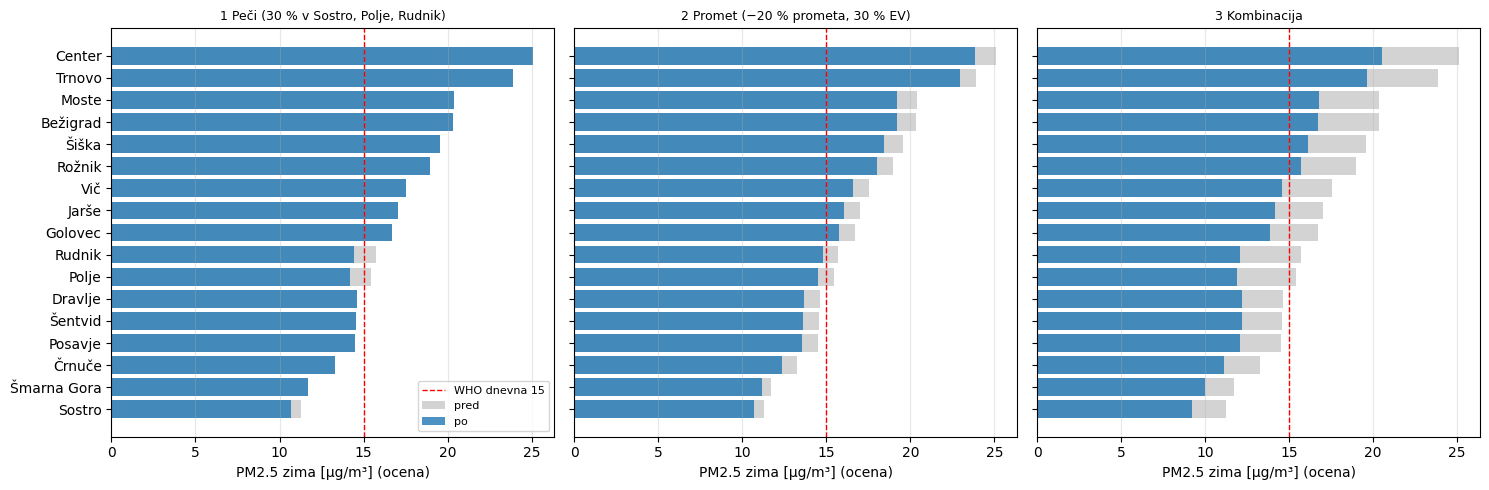

In [6]:
fig, axes = plt.subplots(1, 3, figsize=(15, 5), sharey=True)
for ax, s in zip(axes, (S1, S2, S3)):
    t = s.sort_values("pm25_pred", ascending=False)
    ax.barh(t.index, t.pm25_pred, color="lightgray", label="pred")
    ax.barh(t.index, t.pm25_po, color="tab:blue", alpha=.8, label="po")
    ax.axvline(MEJA_DAN, color="red", ls="--", lw=1, label=f"WHO dnevna {MEJA_DAN}")
    ax.set_title(s.attrs["ime"], fontsize=9); ax.invert_yaxis(); ax.grid(alpha=.3, axis="x"); ax.set_xlabel("PM2.5 zima [µg/m³] (ocena)")
axes[0].legend(fontsize=8); plt.tight_layout(); plt.show()

## 5. Karta pred / po (scenarij 3)

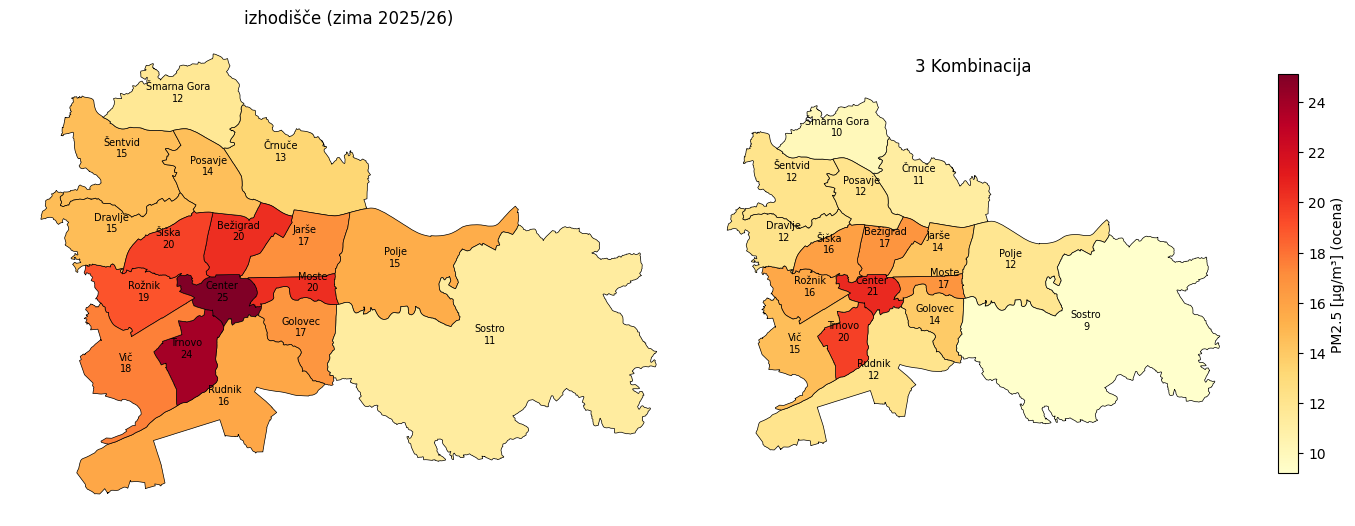

In [7]:
g = cs.set_index("cs_ime").join(S3[["pm25_pred", "pm25_po", "sprememba_%"]])
fig, axes = plt.subplots(1, 2, figsize=(14, 6))
vmin, vmax = g.pm25_po.min(), g.pm25_pred.max()
for ax, col, naslov in zip(axes, ["pm25_pred", "pm25_po"], ["izhodišče (zima 2025/26)", S3.attrs["ime"]]):
    g.plot(column=col, cmap="YlOrRd", vmin=vmin, vmax=vmax, legend=(col == "pm25_po"), edgecolor="black", linewidth=.5, ax=ax,
           legend_kwds={"label": "PM2.5 [µg/m³] (ocena)", "shrink": .7})
    for ime, row in g.iterrows():
        p = row.geometry.representative_point(); ax.annotate(f"{ime}\n{row[col]:.0f}", (p.x, p.y), ha="center", fontsize=7)
    ax.set_title(naslov); ax.set_axis_off()
plt.tight_layout(); plt.show()

## 6. Kje zamenjava peči največ prinese (prioritizacija)

Učinek 1.000 zamenjanih peči na prebivalstveno uteženo mestno povprečje, po ČS: odvisen je od gostote kurišč in od števila ljudi, ki tam živijo. Prikaz odgovarja na vprašanje "s katero ČS začeti".

In [8]:
rows = []
for c in k.index:
    n = k.loc[c, "kurisca_trda_ocena"]
    if n < 100: continue
    delez = min(1.0, 1000 / n)
    s = scenarij(c, zamenjava={c: delez})
    m = s.attrs["mesto"]
    rows.append(dict(cs=c, kurisca=round(n), zamenjanih=round(delez * n), znizanje_v_cs=round(s.loc[c, "pm25_pred"] - s.loc[c, "pm25_po"], 2),
                     znizanje_mesto_utezeno=round(m.pm25_pred - m.pm25_po, 3), stanovanja=int(k.loc[c, "stanovanja"])))
prio = pd.DataFrame(rows).sort_values("znizanje_mesto_utezeno", ascending=False).reset_index(drop=True)
prio

,cs,kurisca,zamenjanih,znizanje_v_cs,znizanje_mesto_utezeno,stanovanja
0,Center,228,228,10.65,1.212,15347
1,Šiška,620,620,6.73,0.956,19146
2,Bežigrad,547,547,7.29,0.948,17539
3,Trnovo,1059,1000,9.84,0.508,6956
4,Moste,286,286,7.33,0.507,9327
5,Rožnik,964,964,6.74,0.379,7587
6,Vič,789,789,5.67,0.285,6775
7,Jarše,542,542,5.28,0.256,6528
8,Golovec,315,315,5.04,0.185,4935
9,Dravlje,674,674,3.47,0.175,6799


## 7. Igrifikacija: proračun in cilj

Cene so **izhodiščne vrednosti, prilagodite jih** (celica `CENE`): povprečni strošek zamenjave peči ali kotla na drva s sodobno napravo oziroma toplotno črpalko in strošek priključitve na vročevod sta reda nekaj tisoč evrov na stavbo; deleža subvencije (Eko sklad) ne vgrajujemo, ker se spreminja. Prometnih ukrepov ne vrednotimo v evrih (gre za politiko, ne nakup).

Igra: z danim proračunom izberi ČS in ukrepe, da čim bolj znižaš prebivalstveno uteženo povprečje ali število dni nad mejo. Spodnja celica naredi preprosto "požrešno" izbiro: vsak evro gre tja, kjer prinese največ.

porabljeno 4.8 M EUR, zamenjanih 800 peči; mesto 18.6 → 16.5 µg/m³ (-11 %)
razporeditev: {'Center': 200, 'Moste': 200, 'Bežigrad': 400}


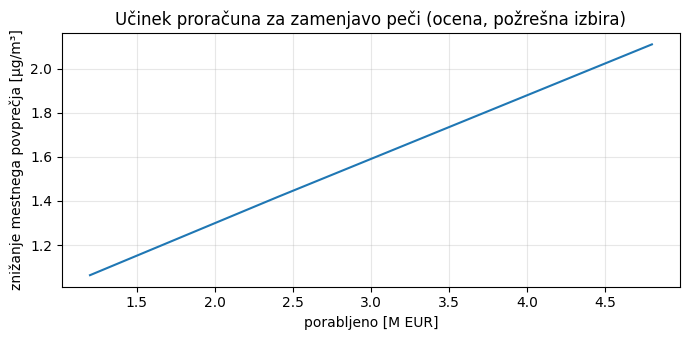

In [9]:
CENE = {"zamenjava_peci_eur": 6000, "prikljucitev_vrocevod_eur": 8000}   # privzeto, prilagodite (brez subvencij)
PRORACUN = 5_000_000   # EUR

def igra(proracun, korak=200):
    """Požrešno: v vsakem koraku zamenja `korak` peči v ČS, kjer je učinek na evro največji (upošteva že porabljeno)."""
    zamenjano = {c: 0.0 for c in k.index}; porabljeno = 0; zgodovina = []
    while porabljeno + korak * CENE["zamenjava_peci_eur"] <= proracun:
        najboljsa, najboljsi_ucinek = None, 0
        for c in k.index:
            n = k.loc[c, "kurisca_trda_ocena"]
            if zamenjano[c] + korak > n: continue
            z = {cc: zamenjano[cc] / k.loc[cc, "kurisca_trda_ocena"] for cc in k.index}; z[c] = (zamenjano[c] + korak) / n
            m = scenarij("", zamenjava=z).attrs["mesto"]
            if m.pm25_pred - m.pm25_po > najboljsi_ucinek: najboljsa, najboljsi_ucinek = c, m.pm25_pred - m.pm25_po
        if najboljsa is None: break
        zamenjano[najboljsa] += korak; porabljeno += korak * CENE["zamenjava_peci_eur"]
        zgodovina.append((porabljeno, najboljsi_ucinek))
    return zamenjano, porabljeno, zgodovina

zam, por, zg = igra(PRORACUN)
rez = scenarij(f"igra: {PRORACUN/1e6:.0f} M EUR", zamenjava={c: zam[c] / k.loc[c, "kurisca_trda_ocena"] for c in k.index})
m = rez.attrs["mesto"]
print(f"porabljeno {por/1e6:.1f} M EUR, zamenjanih {sum(zam.values()):,.0f} peči; mesto {m.pm25_pred:.1f} → {m.pm25_po:.1f} µg/m³ ({m['sprememba_%']:+.0f} %)")
print("razporeditev:", {c: int(v) for c, v in zam.items() if v > 0})
plt.figure(figsize=(7, 3.5)); plt.plot([x[0] / 1e6 for x in zg], [x[1] for x in zg]); plt.xlabel("porabljeno [M EUR]"); plt.ylabel("znižanje mestnega povprečja [µg/m³]")
plt.title("Učinek proračuna za zamenjavo peči (ocena, požrešna izbira)"); plt.grid(alpha=.3); plt.tight_layout(); plt.show()

## 8. Omejitve, ki jih mora vsak uporabnik razumeti

- Deleži virov za mesto in uteži prometa so predpostavke (ena celica); razporeditev kurišč po ČS je iz GRAL, a GRAL je model enega vira za meteorologijo leta 2021, vzhodni rob MOL pa je zunaj mreže.
- Model je linearen; v resnici sekundarni delci in meteorologija učinke spreminjajo (ob inverziji lokalni viri štejejo več kot v povprečju).
- Ocena kurišč po ČS je iz zvezka 04 (registri + EviDim), pravilna po redu velikosti.
- Dnevni potek po ČS je prevzet z Bežigrada; epizode so v resnici v nižjih ČS močnejše.
- Rezultati so smiselni za **primerjavo ukrepov med seboj**, ne kot napoved absolutnih vrednosti.

## Kaj lahko ekipa iz tega naredi

1. **Načrtovalnik ukrepov za občino:** spletni vmesnik z drsniki po ČS, takojšnjim izračunom in karto; izvoz "akcijskega načrta" (kje, koliko, koliko stane, kaj prinese).
2. **Igra za občane:** proračun, cilj (npr. prepoloviti dni nad mejo), točke; pokaže, da regionalno ozadje omejuje, kaj mesto lahko doseže samo.
3. **Finejše z GRAL:** namesto po ČS računati na mreži 250 m (`gral_kurisca_urno_250m.nc` in `emisije_kurisca_250m.*` sta na isti mreži): ukrep "zamenjava peči v tem območju" in njegov učinek po ulicah; z `gral_promet_*` (samo relativno) tudi prometne ukrepe prostorsko.
4. **Povezava z zvezkom 06:** ko je ukrep izveden, ga preveriti z meteorološko normalizacijo meritev.
5. **Stroškovna učinkovitost:** dodati subvencije, življenjsko dobo naprav in zdravstvene koristi (npr. metodologija WHO AirQ+) za primerjavo v evrih.